# Statistics, Probability, & Machine Learning for Physicists
### An Accelerated, Interactive Reference Guide

Welcome! This notebook is designed specifically for someone with a background in physics. It skips the programming basics and dives straight into the mathematical definitions, Python implementations (`scipy.stats`, `numpy`, `matplotlib`, `scikit-learn`), and interactive plots of core probability distributions, statistical concepts, and machine learning models.

---

## 1. Core Probability Distributions

In physics, you often see probability densities as square-wavefunctions ($|\psi|^2$) or partition functions. In statistics, we define them via Probability Mass Functions (**PMF** for discrete variables) or Probability Density Functions (**PDF** for continuous variables).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA

# Set plotting style for clear visibility
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
print("Libraries successfully imported!")

Libraries successfully imported!


### A. Poisson & Binomial (Discrete)
* **Poisson:** Models counts of independent events in fixed intervals (identical math to radioactive decay counters).
* **Binomial:** Models the number of successes in $n$ independent Bernoulli trials (binary choices).

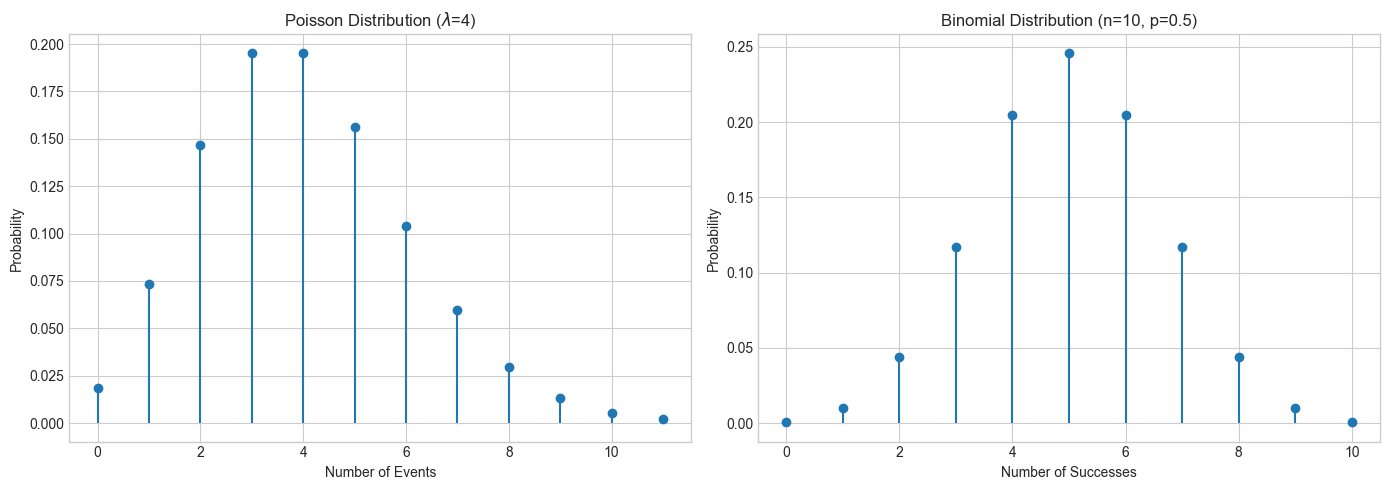

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Poisson Distribution (lambda = 4)
lam = 4
x_poi = np.arange(0, 12)
pmf_poi = stats.poisson.pmf(x_poi, lam)
ax1.stem(x_poi, pmf_poi, basefmt=" ")
ax1.set_title(f'Poisson Distribution ($\lambda$={lam})')
ax1.set_xlabel('Number of Events')
ax1.set_ylabel('Probability')

# Binomial Distribution (n = 10, p = 0.5)
n, p = 10, 0.5
x_bin = np.arange(0, 11)
pmf_bin = stats.binom.pmf(x_bin, n, p)
ax2.stem(x_bin, pmf_bin, basefmt=" ")
ax2.set_title(f'Binomial Distribution (n={n}, p={p})')
ax2.set_xlabel('Number of Successes')
ax2.set_ylabel('Probability')

plt.tight_layout()
plt.show()

### B. Normal & Exponential (Continuous)
* **Normal (Gaussian):** The cornerstone of statistics due to the Central Limit Theorem.
* **Exponential:** Models the continuous time between independent random events.

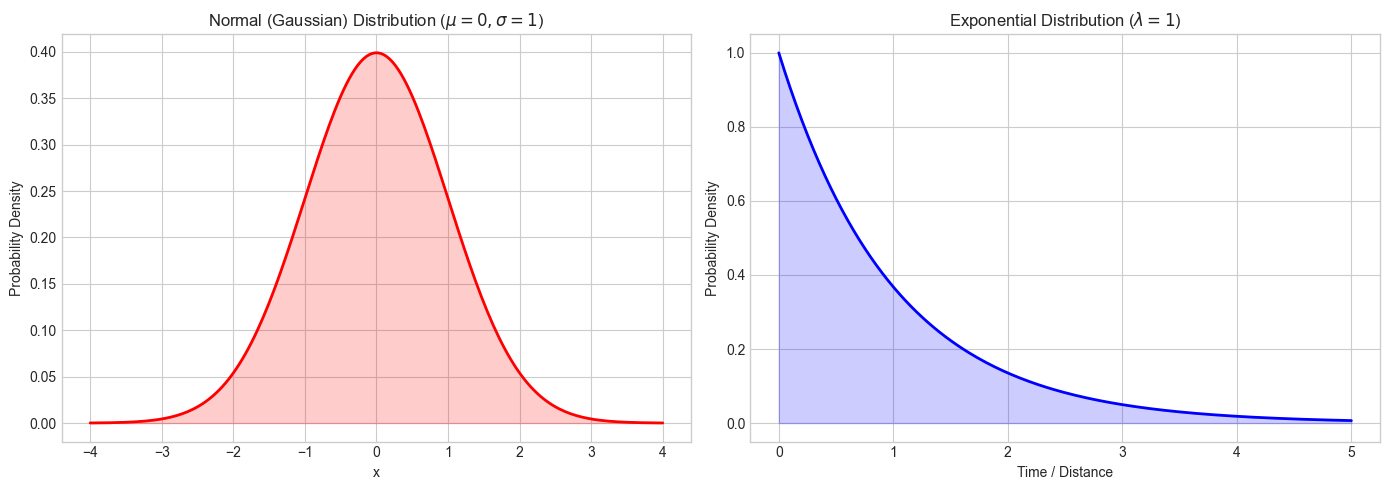

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Normal Distribution (mu=0, sigma=1)
x_norm = np.linspace(-4, 4, 200)
pdf_norm = stats.norm.pdf(x_norm, 0, 1)
ax1.plot(x_norm, pdf_norm, 'r-', lw=2)
ax1.fill_between(x_norm, pdf_norm, alpha=0.2, color='red')
ax1.set_title('Normal (Gaussian) Distribution ($\mu=0, \sigma=1$)')
ax1.set_xlabel('x')
ax1.set_ylabel('Probability Density')

# Exponential Distribution (scale = 1/lambda)
x_exp = np.linspace(0, 5, 200)
pdf_exp = stats.expon.pdf(x_exp, scale=1)
ax2.plot(x_exp, pdf_exp, 'b-', lw=2)
ax2.fill_between(x_exp, pdf_exp, alpha=0.2, color='blue')
ax2.set_title('Exponential Distribution ($\lambda=1$)')
ax2.set_xlabel('Time / Distance')
ax2.set_ylabel('Probability Density')

plt.tight_layout()
plt.show()

---
## 2. Statistical Inference

### Maximum Likelihood Estimation (MLE)
MLE treats parameters as fixed variables and seeks to maximize the likelihood function $L(\theta|X) = \prod P(x_i|\theta)$. In practice, we minimize the **Negative Log-Likelihood (NLL)**, turning products into sums—exactly how you derive thermodynamic potentials!

In [4]:
# Generate random sample data from a hidden Normal Distribution
np.random.seed(42)
true_mu, true_sigma = 5.0, 2.0
data = np.random.normal(true_mu, true_sigma, size=100)

# Fit parameters using Maximum Likelihood Estimation
estimated_mu, estimated_sigma = stats.norm.fit(data)

print(f"True Mean: {true_mu} | MLE Estimated Mean: {estimated_mu:.3f}")
print(f"True Sigma: {true_sigma} | MLE Estimated Sigma: {estimated_sigma:.3f}")

True Mean: 5.0 | MLE Estimated Mean: 4.792
True Sigma: 2.0 | MLE Estimated Sigma: 1.807


---
## 3. Core Machine Learning Models

### A. Linear & Logistic Regression

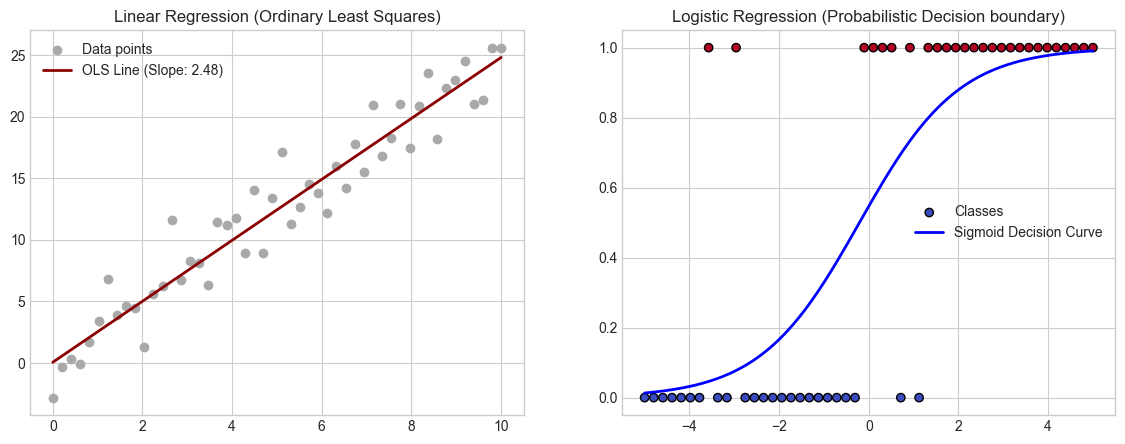

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Linear Regression Example
X_lin = np.linspace(0, 10, 50).reshape(-1, 1)
y_lin = 2.5 * X_lin + np.random.normal(0, 2, size=(50, 1))
lin_model = LinearRegression().fit(X_lin, y_lin)

ax1.scatter(X_lin, y_lin, color='darkgray', label='Data points')
ax1.plot(X_lin, lin_model.predict(X_lin), color='darkred', lw=2, label=f'OLS Line (Slope: {lin_model.coef_[0][0]:.2f})')
ax1.set_title('Linear Regression (Ordinary Least Squares)')
ax1.legend()

# 2. Logistic Regression (Binary Classification)
X_log = np.linspace(-5, 5, 50).reshape(-1, 1)
y_log = (1 / (1 + np.exp(-X_log)) > np.random.rand(50, 1)).astype(int).ravel()
log_model = LogisticRegression().fit(X_log, y_log)

X_test = np.linspace(-5, 5, 200).reshape(-1, 1)
prob = log_model.predict_proba(X_test)[:, 1]

ax2.scatter(X_log, y_log, c=y_log, cmap='coolwarm', edgecolors='k', label='Classes')
ax2.plot(X_test, prob, color='blue', lw=2, label='Sigmoid Decision Curve')
ax2.set_title('Logistic Regression (Probabilistic Decision boundary)')
ax2.legend()

plt.show()

### B. Unsupervised Learning: Principal Component Analysis (PCA)
In physics, finding principal axes of inertia involves diagonalizing a tensor. In ML, PCA finds the eigenvectors of the data's covariance matrix to reduce dimensionality.

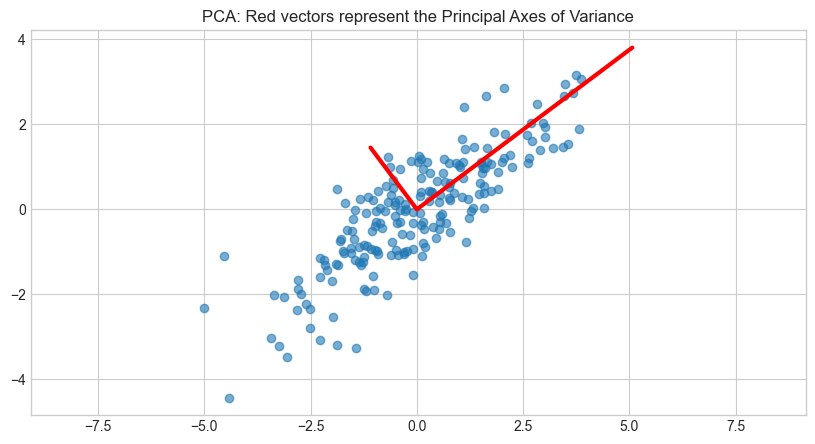

In [6]:
# Correlated 2D data
rng = np.random.default_rng(42)
pts = rng.multivariate_normal([0, 0], [[3, 2], [2, 2]], size=200)

pca = PCA(n_components=2)
pca.fit(pts)

plt.scatter(pts[:, 0], pts[:, 1], alpha=0.6)
for length, vector in zip(pca.explained_variance_, pca.components_):
    v = vector * 3 * np.sqrt(length) # scale vector for display
    plt.plot([0, v[0]], [0, v[1]], '-r', lw=3)

plt.axis('equal')
plt.title('PCA: Red vectors represent the Principal Axes of Variance')
plt.show()